感知器實做
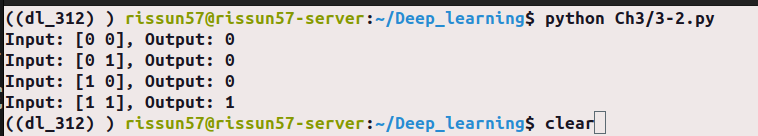

In [2]:
import numpy as np

class Perceptron:
    def __init__(self, input_size, weights=None, bias=None):
        if weights is None:
            self.weights = np.ones(input_size)*1
        else:
            self.weights = weights
        if bias is None:
            self.bias = -1
        else:
            self.bias = bias

    @staticmethod
    def activation_function(x):
        if x>0:
            return 1
        return 0

    def __call__(self, input_data):
        weighted_sum = np.dot(input_data, self.weights) + self.bias
        return self.activation_function(weighted_sum)

# main
weights = np.array([1, 1])
# use -1 if AND Gate, OR Gate use -0.5, NAND Gate use -1.5 bias = 1.5
# use NOR Gate use 0.5
bias = 0.5
# AND
AND_Gate = Perceptron(input_size=2, weights=weights, bias=bias)
# OR
OR_Gate = Perceptron(input_size=2, weights=weights, bias=bias)
# NAND
NAND_Gate = Perceptron(input_size=2, weights=[-1.0, -1.0], bias=bias)
# NOR
NOR_Gate = Perceptron(input_size=2, weights=[-1.0, -1.0], bias=bias)

input_data = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])

for data in input_data:
    #output = AND_Gate(data)
    #output = OR_Gate(data)
    #output = NAND_Gate(data)
    output = NOR_Gate(data)
    print(f"Input: {data}, Output: {output}")

Input: [0 0], Output: 1
Input: [0 1], Output: 0
Input: [1 0], Output: 0
Input: [1 1], Output: 0


邏輯閘真值表 (00,01,10,11)權重 w偏差 b各輸入之加權總和 z=w⋅x+b 與輸出驗證AND[0, 0, 0, 1][1.0, 1.0]-1.5• $(0, 0) \rightarrow -1.5 \le 0 \rightarrow 0$• $(0, 1) / (1, 0) \rightarrow -0.5 \le 0 \rightarrow 0$• $(1, 1) \rightarrow 0.5 > 0 \rightarrow \mathbf{1}$OR[0, 1, 1, 1][1.0, 1.0]-0.5• $(0, 0) \rightarrow -0.5 \le 0 \rightarrow 0$• $(0, 1) / (1, 0) \rightarrow 0.5 > 0 \rightarrow \mathbf{1}$• $(1, 1) \rightarrow 1.5 > 0 \rightarrow \mathbf{1}$NAND[1, 1, 1, 0][-1.0, -1.0]1.5• $(0, 0) \rightarrow 1.5 > 0 \rightarrow \mathbf{1}$• $(0, 1) / (1, 0) \rightarrow 0.5 > 0 \rightarrow \mathbf{1}$• $(1, 1) \rightarrow -0.5 \le 0 \rightarrow 0$NOR[1, 0, 0, 0][-1.0, -1.0]0.5• $(0, 0) \rightarrow 0.5 > 0 \rightarrow \mathbf{1}$• $(0, 1) / (1, 0) \rightarrow -0.5 \le 0 \rightarrow 0$• $(1, 1) \rightarrow -1.5 \le 0 \rightarrow 0$


In [3]:
!pip install tensorflow
# 1. 驗證 GPU 是否已啟用
import tensorflow as tf

gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f"✅ GPU 成功啟用！偵測到裝置: {gpus[0].name}")
else:
    print("❌ 目前仍為 CPU 模式，請確認 Colab 執行階段是否已切換為 T4 GPU！")

import numpy as np
import pandas as pd
from keras import Sequential
from keras.layers import Dense, Input
from keras.utils import to_categorical


# 2. 固定隨機種子
np.random.seed(100)
tf.random.set_seed(100)  # 同時固定 TensorFlow/Keras 底層的 GPU 隨機種子

# 3. 讀取與處理資料
url = "https://raw.githubusercontent.com/plotly/datasets/master/diabetes.csv"
data = pd.read_csv(url)
data_set = data.values
np.random.shuffle(data_set)

x = data_set[:, 0:8]
x -= x.mean(axis=0)
x /= x.std(axis=0)
y = data_set[:, 8]
y = to_categorical(y, num_classes=2)

# 4. 搭建模型
model = Sequential([
    Input(shape=(8,)),
    Dense(8,kernel_initializer='he_uniform',
          bias_initializer='zeros',activation='relu'),
    Dense(8, kernel_initializer='he_uniform',
          bias_initializer='zeros', activation='relu'),
    Dense(2, kernel_initializer='he_uniform',
          bias_initializer='zeros', activation='softmax')
])

model.summary()

# 5. 編譯與訓練 (自動在 GPU 執行)
model.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

model.fit(
    x,
    y,
    epochs=150,
    batch_size=10,
    verbose=0
)
loss, accuracy = model.evaluate(x, y)
print(f"Loss: {loss}, Accuracy: {accuracy}")

❌ 目前仍為 CPU 模式，請確認 Colab 執行階段是否已切換為 T4 GPU！


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8)              │            72 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │            72 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │            18 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 162 (648.00 B)

 Trainable params: 162 (648.00 B)

 Non-trainable params: 0 (0.00 B)

24/24 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8164 - loss: 0.4001  
Loss: 0.4000878632068634, Accuracy: 0.81640625


In [3]:
!lscpu
!nproc

Architecture:                x86_64
  CPU op-mode(s):            32-bit, 64-bit
  Address sizes:             48 bits physical, 48 bits virtual
  Byte Order:                Little Endian
CPU(s):                      2
  On-line CPU(s) list:       0,1
Vendor ID:                   AuthenticAMD
  Model name:                AMD EPYC 7B12
    CPU family:              23
    Model:                   49
    Thread(s) per core:      2
    Core(s) per socket:      1
    Socket(s):               1
    Stepping:                0
    BogoMIPS:                4499.99
    Flags:                   fpu vme de pse tsc msr pae mce cx8 apic sep mtrr pg
                             e mca cmov pat pse36 clflush mmx fxsr sse sse2 ht s
                             yscall nx mmxext fxsr_opt pdpe1gb rdtscp lm constan
                             t_tsc rep_good nopl nonstop_tsc cpuid extd_apicid t
                             sc_known_freq pni pclmulqdq ssse3 fma cx16 sse4_1 s
                             se4_2 